# 비텍스트 RAG 실습 — 표 추출 · 청킹 · 검색분리


> PDF 속 **표**는 단순 추출하면 행·열이 깨진다.
> 표를 **살려서 꺼내고 → 청킹하고 → 검색 가능하게** 담는 기초를 익힌다.

| 단계 | 내용 |
|------|------|
| 1️⃣ 이론 | 왜 단순 추출이 표를 깨뜨리나 (코드 없음) |
| 2️⃣ 기본 | 샘플 PDF 만들기 · 단순추출 vs 구조보존 |
| 3️⃣ 응용 | ① 작은 표 1청크 ② 큰 표 머리글 복제 |
| 4️⃣ 데이터 활용 | 검색/원본 분리 · 단순 vs 구조보존 비교 · 검수 |


# 1️⃣ 단계 — 이론 

## PDF엔 "구조 정보"가 없다

```
 PDF의 실체 = "글자 + 그 글자의 (x, y) 좌표"의 모음
   → "여기가 표다 / 문단이다" 라는 구조 정보가 없음
```

## 단순 추출이 깨뜨리는 것

```
 표가 의미를 담는 방식 = 셀의 위치(행, 열)
   | 구분 | 매출 | 증감 |      ← (해외) 와 (-3%) 가
   | 해외 | 85억 | -3% |        '같은 행'이라 연결됨

 단순 추출기는 좌표를 무시하고 읽는 순서대로 일렬로 뽑음
   "구분 매출 증감 해외 85억 -3% ..."
     └─ 어느 값이 어느 항목? 2차원 → 1차원 붕괴 ❌
```

## 해결 — 3단계로 다진다

```
 ① 구조 보존 추출  좌표·선을 분석해 행·열을 복원
 ② 표 청킹         작은 표=통째 1청크 / 큰 표=머리글 복제
 ③ 검색·답변 분리  검색=요약(정확) / 답변=원본(완전)
                   + 추출 결과는 반드시 검수
```


# 2️⃣ 단계 — 샘플 PDF 만들기 · 단순추출 vs 구조보존

### 셀 1 — 도구 설치

In [1]:
!pip install -q reportlab pypdf pdfplumber

# ── Pillow 설치 점검 ───────────────────────────────────────────────
# Colab에서 Pillow가 섞여 설치되면(ImageText.py는 12.x, _typing.py는 11.x)
#   ImportError: cannot import name '_Ink' from 'PIL._typing'
# 가 납니다. 아래에서 자동으로 감지해 깨끗이 재설치합니다.
import subprocess, sys

try:
    import PIL.ImageDraw          # ← 여기서 ImageText 를 끌어옵니다
    import PIL
    print(f"✅ Pillow {PIL.__version__} 정상")
except ImportError as e:
    print(f"⚠️ Pillow 설치가 깨져 있습니다: {e}")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "--force-reinstall", "--no-cache-dir", "pillow"], check=True)
    print("🔧 Pillow 재설치 완료 → [런타임] → [세션 다시 시작] 후 이어서 실행하세요")
# ──────────────────────────────────────────────────────────────────

✅ Pillow 12.3.0 정상



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


**이 셀이 한 일**: 실습 도구를 설치했습니다.
`reportlab`(PDF 생성) · `pypdf`(단순 추출) · `pdfplumber`(구조 보존 추출).


### 셀 2 — 표가 든 샘플 PDF 만들기

다음 셀들의 재료로 쓸, **표 1개가 든 PDF**를 코드로 만듭니다.


In [2]:
table_data = [
    ["구분", "매출", "증감"],   # 머리글 행
    ["국내", "120억", "+8%"],
    ["해외", "85억",  "-3%"],
    ["온라인", "47억", "+15%"],
]

from reportlab.lib.pagesizes import A4
from reportlab.lib import colors
from reportlab.platypus import SimpleDocTemplate, Table, TableStyle, Paragraph, Spacer
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.pdfbase import pdfmetrics
from reportlab.pdfbase.cidfonts import UnicodeCIDFont

pdfmetrics.registerFont(UnicodeCIDFont("HYSMyeongJo-Medium"))   # 한글 글리프
styles = getSampleStyleSheet()
for name in ("Title", "Normal"):
    styles[name].fontName = "HYSMyeongJo-Medium"

pdf_table = Table(table_data)
pdf_table.setStyle(TableStyle([
    ("GRID", (0, 0), (-1, -1), 0.5, colors.black),               # 격자선
    ("FONTNAME", (0, 0), (-1, -1), "HYSMyeongJo-Medium"),
]))

SimpleDocTemplate("sample_report.pdf", pagesize=A4).build([
    Paragraph("2026년 1분기 실적 보고", styles["Title"]),
    Spacer(1, 12),
    Paragraph("[표 1] 부문별 매출 현황", styles["Normal"]),       # ← 표 캡션
    Spacer(1, 6),
    pdf_table,
])
print("✅ sample_report.pdf 생성 완료")

✅ sample_report.pdf 생성 완료


**이 셀이 한 일**: 제목·캡션·**표**가 든 PDF를 만들었습니다.
표에 격자선을 넣어 추출기가 '선'으로 표를 인식할 수 있게 했습니다.


### 셀 3 — 단순 텍스트 추출 (표가 깨지는 쪽)

`pypdf` 로 글자만 뽑습니다. 좌표를 무시하므로 표가 한 줄로 뭉개집니다.


In [3]:
import pypdf

reader = pypdf.PdfReader("sample_report.pdf")
raw_text = reader.pages[0].extract_text()

print("───── 단순 추출 결과 ─────")
print(raw_text)

───── 단순 추출 결과 ─────
2026년 1분기 실적 보고
[표 1] 부문별 매출 현황
구분
매출
증감
국내
120억
+8%
해외
85억
-3%
온라인
47억
+15%



**이 셀이 한 일**: 글자만 단순 추출했습니다.

> ⚠️ "구분 / 매출 / 증감"이 어느 셀과 짝인지 사라졌습니다.
> *"해외 매출 증감률?"* 을 물으면 → "-3%? 85억? 헷갈림".
> **행·열 붕괴**를 직접 확인한 것입니다.


### 셀 4 — 구조 보존 추출 (표가 살아나는 쪽)

`pdfplumber` 는 글자의 **좌표·선을 분석**해 *"같은 y = 같은 행"* 으로
표 구조를 복원합니다.


In [4]:
import pdfplumber

with pdfplumber.open("sample_report.pdf") as pdf:
    extracted_table = pdf.pages[0].extract_tables()[0]   # 2차원 리스트

for row in extracted_table:
    print(row)

['구분', '매출', '증감']
['국내', '120억', '+8%']
['해외', '85억', '-3%']
['온라인', '47억', '+15%']


**이 셀이 한 일**: 표를 **행·열 구조 그대로** 추출했습니다.

> 💡 셀 3과 비교하세요. `['해외', '85억', '-3%']` 처럼
> 한 행이 묶여 **관계가 살아 있습니다.** 이제 *"해외 매출 증감률?"*
> → 정확히 **"-3%"** 라고 답할 수 있는 형태입니다.

> | 도구 | 강점 | 비용 |
> |------|------|------|
> | LlamaParse | 복잡 표 → 마크다운 품질 최상 | 페이지당 과금 |
> | Unstructured | 형식 다양성(PDF·PPT·docx) | 오픈소스 무료 |
> | Docling | 표 구조·읽기순서 보존 특화 | 오픈소스 무료 |
> | pdfplumber | 가볍고 빠른 표 추출(실습용) | 오픈소스 무료 |


# 3️⃣ 단계 — 표를 RAG에 담는 형태로 만들기

## ① 작은 표 → 마크다운 1청크

### 셀 5 — 표를 마크다운으로 변환 (LLM이 잘 읽는 형식)

작은 표(~20행)는 **표 1개 = 1청크**. 행 도중에 쪼개지 않습니다.
+ **캡션을 맥락 한 줄로** 붙여 "무엇에 대한 표인지" 알 수 있게 합니다.


In [6]:
def table_to_markdown(rows):
    header = "| " + " | ".join(rows[0]) + " |"
    divider = "| " + " | ".join(["---"] * len(rows[0])) + " |"
    body = ["| " + " | ".join(r) + " |" for r in rows[1:]]
    return "\n".join([header, divider] + body)

caption = "[표 1] 2026년 1분기 부문별 매출 현황"
table_chunk = caption + "\n" + table_to_markdown(extracted_table)
print(table_chunk)

[표 1] 2026년 1분기 부문별 매출 현황
| 구분 | 매출 | 증감 |
| --- | --- | --- |
| 국내 | 120억 | +8% |
| 해외 | 85억 | -3% |
| 온라인 | 47억 | +15% |


**이 셀이 한 일**: 추출한 표를 **마크다운 표 1청크**로 만들었습니다.

> 💡 마크다운 표는 한 행이 한 줄에 완결돼 LLM이 행·열 관계를
> 정확히 읽습니다. 맨 윗줄 캡션이 표의 맥락을 줍니다.


## ② 큰 표 → 머리글 복제하며 분할

### 셀 6 — 큰 표는 조각마다 머리글 복제

100행짜리 큰 표는 통째 1청크 불가. 행 그룹으로 나누되 —
**매 조각에 머리글 행을 복제**해 붙여야 열 의미가 살아남습니다.


In [8]:
big_table = [
    ["구분", "매출", "증감"],
    ["국내", "120억", "+8%"], ["해외", "85억", "-3%"],
    ["온라인", "47억", "+15%"], ["오프라인", "73억", "-1%"],
    ["B2B", "210억", "+22%"], ["B2C", "88억", "+5%"],
]

header, rows = big_table[0], big_table[1:]

chunk_size = 2
chunks = []
for i in range(0, len(rows), chunk_size):
    block = rows[i:i + chunk_size]
    chunk = [header] + block            # 머리글 복제
    chunks.append(table_to_markdown(chunk))

for n, chunk in enumerate(chunks, 1):
    print(f"───── 조각 {n} ─────")
    print(chunk, "\n")

───── 조각 1 ─────
| 구분 | 매출 | 증감 |
| --- | --- | --- |
| 국내 | 120억 | +8% |
| 해외 | 85억 | -3% | 

───── 조각 2 ─────
| 구분 | 매출 | 증감 |
| --- | --- | --- |
| 온라인 | 47억 | +15% |
| 오프라인 | 73억 | -1% | 

───── 조각 3 ─────
| 구분 | 매출 | 증감 |
| --- | --- | --- |
| B2B | 210억 | +22% |
| B2C | 88억 | +5% | 



**이 셀이 한 일**: 큰 표를 2행씩 나누되 **모든 조각에 머리글을 복제**했습니다.

> 💡 모든 조각의 첫 줄이 `| 구분 | 매출 | 증감 |` 입니다.
> 조각 2, 3을 따로 떼어 검색해도 열 의미가 유지됩니다.
> 큰 표에서 가장 흔한 실수인 **머리글 분실**을 막는 규칙입니다.


# 4️⃣ 단계 — 검색/원본 분리 · 비교 · 검수

### 셀 7 — 검색용 요약 / 답변용 원본 분리

표를 마크다운 그대로 임베딩하면 기호·숫자가 많아 의미 매칭이 약합니다.
그래서 **검색은 '요약'으로, 답변은 '원본'으로** 분리합니다.

```
 색인:  표 ─▶ 요약(검색용)  ─▶ search_index
          └─▶ 원본(답변용) ─▶ docstore        같은 id 로 연결 🔑
 검색:  질문 ─▶ 요약으로 검색 ─▶ id ─▶ docstore에서 원본 꺼내 전달
```


In [11]:
import uuid

table_original = table_chunk                                       # 답변용
table_summary = "2026년 1분기 부문별 매출과 증감률 표. 국내 해외 온라인 매출 실적"  # 검색용

doc_id = str(uuid.uuid4())
docstore     = {doc_id: table_original}   # 답변용 저장소
search_index = {doc_id: table_summary}    # 검색용 저장소

def search(query):
    for _id, summary in search_index.items():
        if any(word in summary for word in query.split()):
            return _id
    return None

found_id = search("해외 매출 증감 알려줘")
print("🔎 검색은 '요약'으로 → id:", found_id[:8])
print("📦 LLM엔 '원본' 전달:\n", docstore[found_id])

🔎 검색은 '요약'으로 → id: 131853c4
📦 LLM엔 '원본' 전달:
 [표 1] 2026년 1분기 부문별 매출 현황
| 구분 | 매출 | 증감 |
| --- | --- | --- |
| 국내 | 120억 | +8% |
| 해외 | 85억 | -3% |
| 온라인 | 47억 | +15% |


**이 셀이 한 일**: `id` 하나로 요약↔원본을 연결했습니다.
검색은 요약(정확), 전달은 원본(완전).

> 💡 그림·차트도 똑같습니다: **그림 → 요약 텍스트(검색용) + 원본 그림(답변용)**.


### 셀 8 — 단순 vs 구조보존, 같은 질문에 답 비교 (핵심!)

같은 질문을 **단순 추출본**과 **구조 보존본**에 던져 답이 어떻게
갈리는지 봅니다. (LLM 없이, 규칙 기반으로 차이만 드러냄)


In [13]:
def answer_from_plain(query):
    # 단순 추출본(1차원 텍스트)에서 질문 단어 주변을 긁어옴
    key = query.split()[0]
    flat = " ".join(raw_text.split())
    idx = flat.find(key)
    return flat[idx:idx + 30] + " ..." if idx >= 0 else "(못 찾음)"

def answer_from_struct(query):
    # 구조 보존본(2차원 표)에서 해당 '행'을 정확히 찾음
    key = query.split()[0]
    head = extracted_table[0]
    for row in extracted_table[1:]:
        if key in row[0]:
            return " / ".join(f"{h}: {v}" for h, v in zip(head, row))
    return "(못 찾음)"

q = "해외 매출 증감"
print(f"🧑 질문: {q}\n")
print("─── 단순 추출 답 ───")
print(answer_from_plain(q))
print("\n─── 구조 보존 답 ───")
print(answer_from_struct(q))

🧑 질문: 해외 매출 증감

─── 단순 추출 답 ───
해외 85억 -3% 온라인 47억 +15% ...

─── 구조 보존 답 ───
구분: 해외 / 매출: 85억 / 증감: -3%


**이 셀이 한 일**: 같은 질문을 두 방식에 던졌습니다.

> ✅ 단순 추출 답은 단어가 뒤섞여 **모호**합니다.
> 구조 보존 답은 `구분: 해외 / 매출: 85억 / 증감: -3%` 처럼 **정확**합니다.
> **같은 문서인데 추출 방식만 달라** 답 품질이 갈립니다.


### 셀 9 — 추출 결과 검수

추출은 한 번에 완벽하지 않습니다. **병합 셀**은 빈칸/`None`으로
깨지기 쉬우니, 추출 직후 빈 셀이 있는지 점검하는 습관을 들입니다.


In [14]:
def validate_table(rows):
    bad = [(r, c) for r, row in enumerate(rows)
                   for c, cell in enumerate(row) if cell in (None, "")]
    return "⚠️ 빈/병합 의심 셀: " + str(bad) if bad else "✅ 이상 없음"

print(validate_table(extracted_table))                 # 정상 표
print(validate_table([["연도", None, None],             # 병합 흉내 표
                       ["2026", "120억", "+8%"]]))

✅ 이상 없음
⚠️ 빈/병합 의심 셀: [(0, 1), (0, 2)]


# 5️⃣ 단계 — 멀티모달: PDF를 '이미지로' 받아들이기

> 지금까지(2~4단계): `pdfplumber`로 표를 **텍스트로** 추출했습니다.
> 그런데 현실의 많은 PDF는 표·차트가 **이미지로 박혀** 있어
> 텍스트 추출이 **0글자**입니다 (스캔 문서, 그림 표, 도표).

```
 [텍스트 추출 가능]          [이미지로 박힌 표]
 pdfplumber → 표 살아남      pdfplumber → 0글자 ❌
        │                          │
        ▼                          ▼ 멀티모달
 4단계까지로 충분            페이지를 이미지로 캡처
                            → 비전 모델이 표를 OCR ✅
```

**핵심 발상**: 텍스트 추출이 안 되면, **PDF 페이지를 그림으로
캡처해 비전 모델(gpt-4o)에게 "이 표를 글자로 옮겨줘"** 라고
시킵니다. (소득세법 세율표 사례에서 검증된 패턴)

### 셀 10 — PDF 페이지를 이미지로 캡처

`pdfplumber`의 `to_image()`로 페이지를 통째로 그림으로
만듭니다. 해상도는 300dpi (표 글자가 또렷해야 비전이 잘 읽음).

캡처 방식: pdfplumber
✅ PDF 1페이지를 이미지로 캡처: (2481, 3508) px


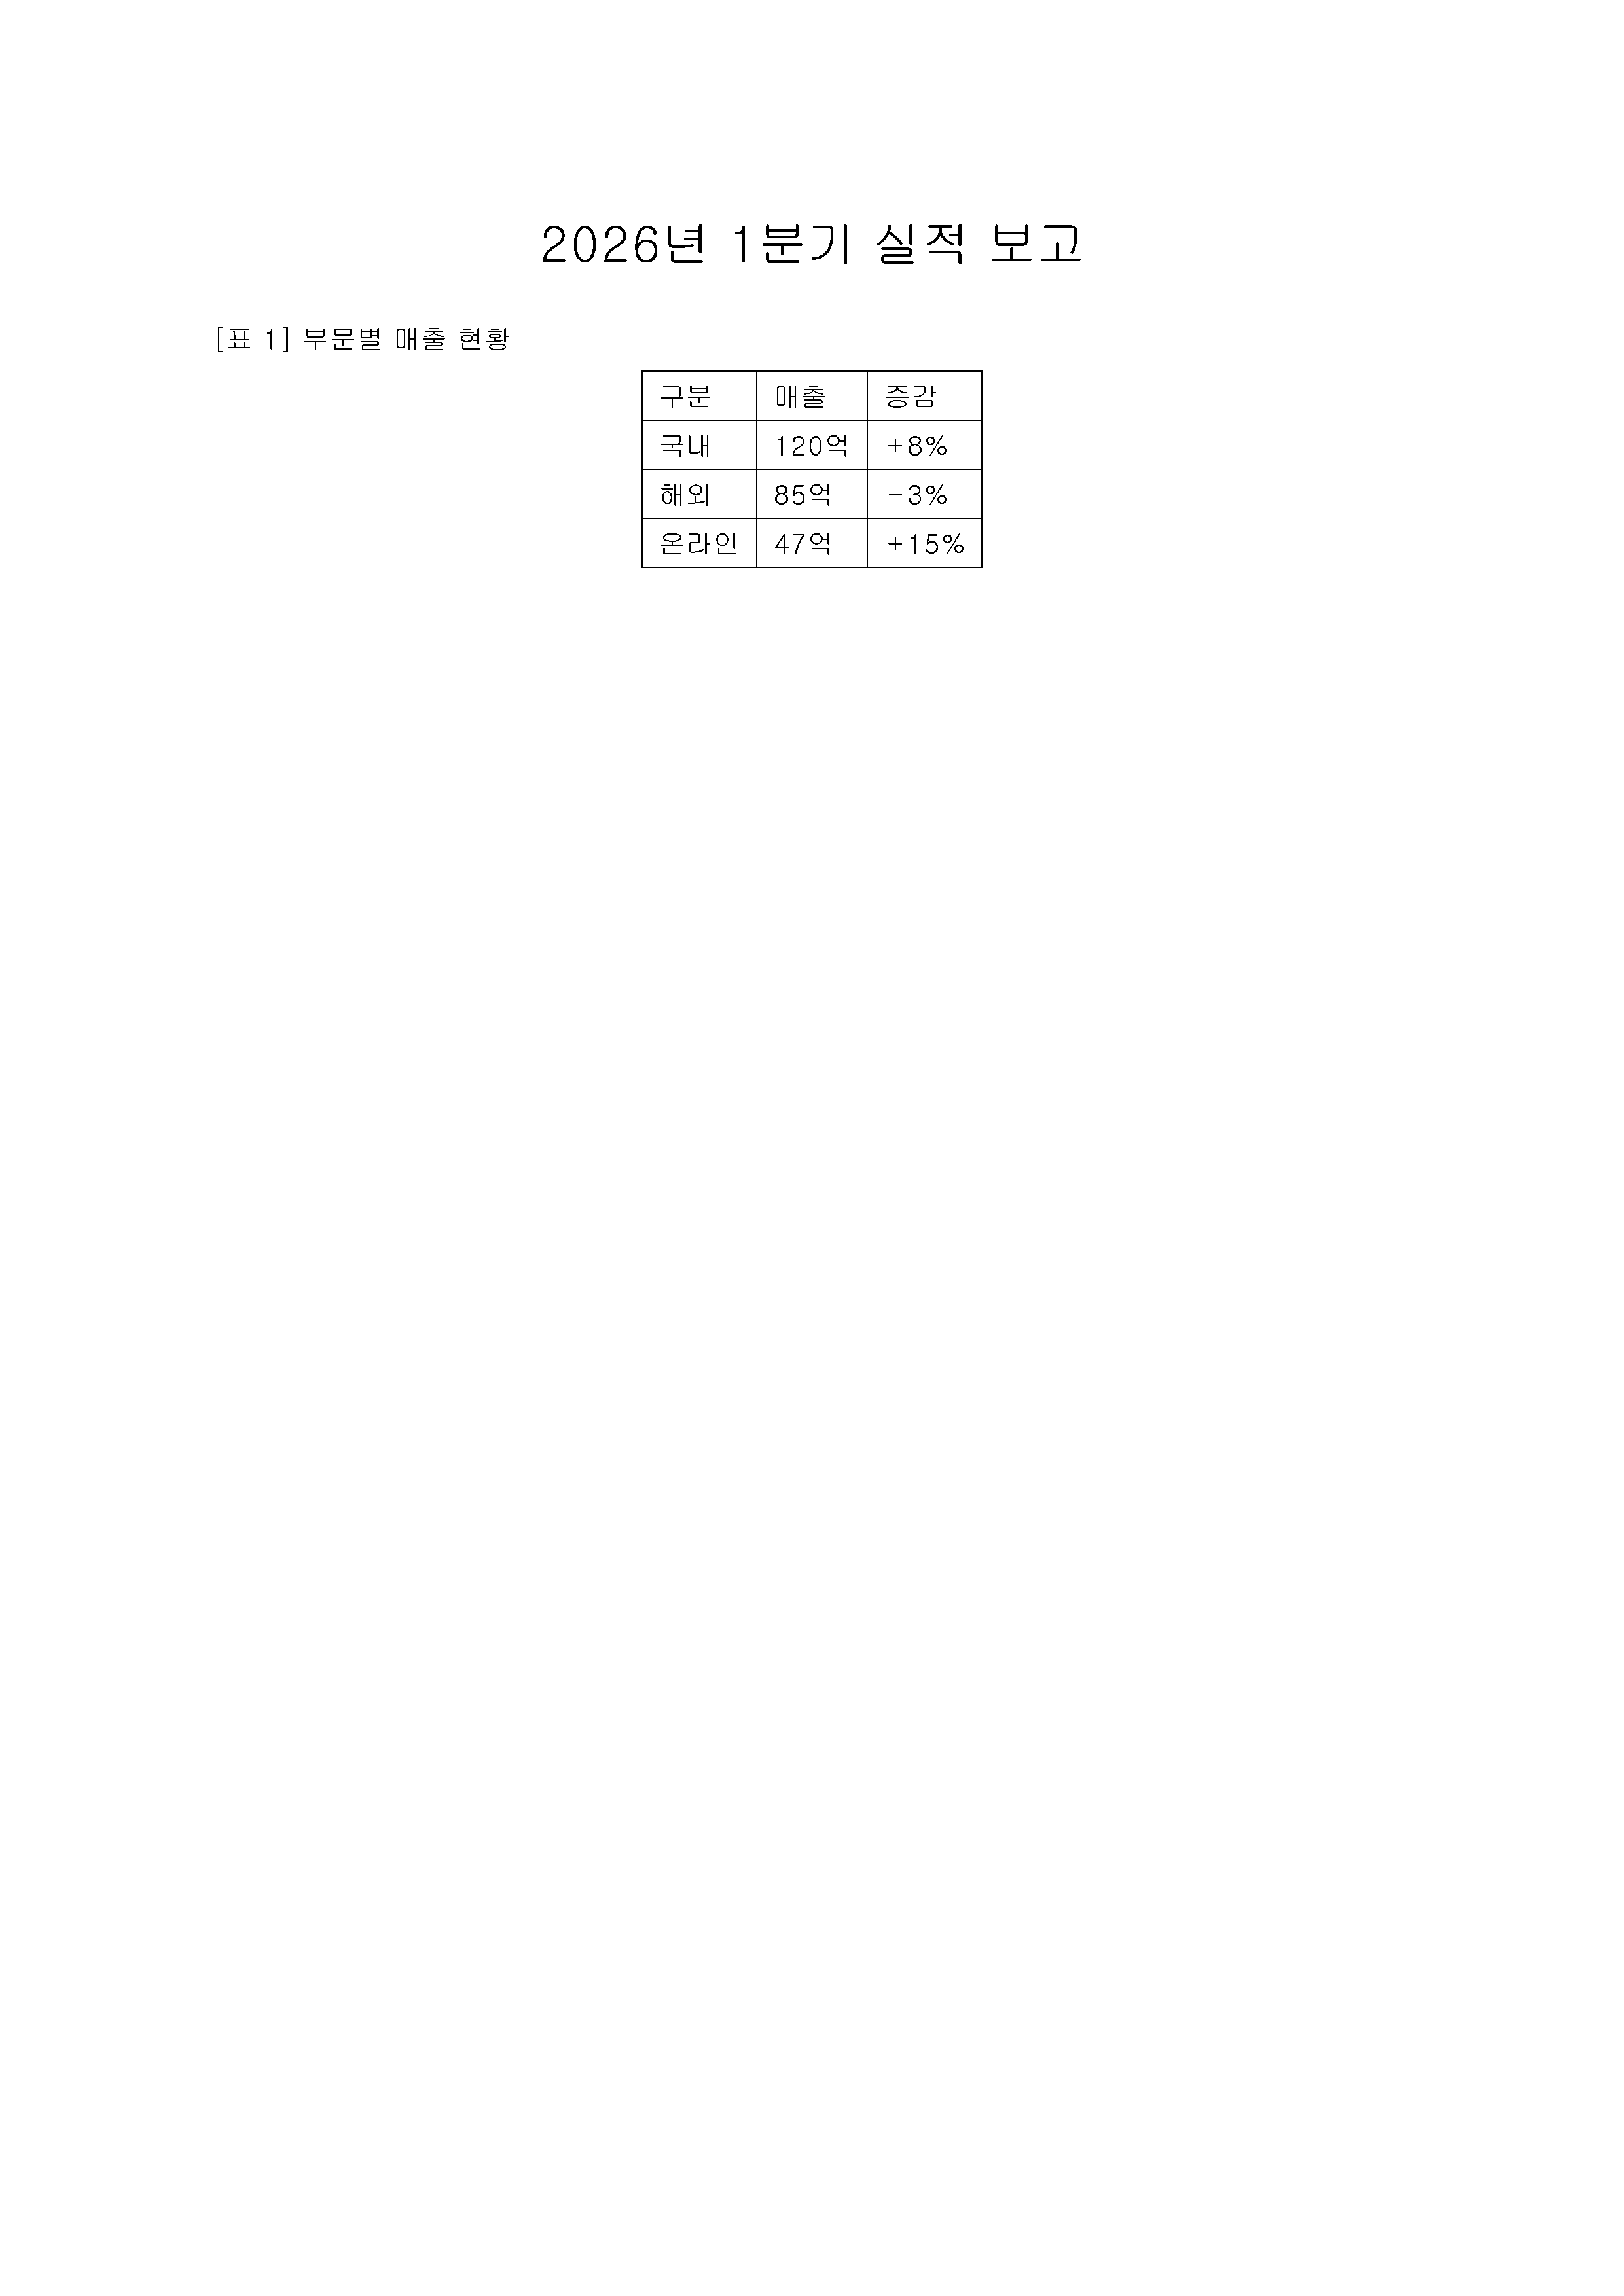

In [19]:
# 4단계까지 만든 sample_report.pdf 를 '이미지'로 캡처
import os

PDF = "/content/sample_report.pdf" if os.path.exists("/content/sample_report.pdf") \
      else "sample_report.pdf"
DPI = 300   # 300dpi = 표의 작은 숫자도 또렷하게 (소득세법서 검증된 값)

try:
    # 1순위: pdfplumber — 내부에서 PIL.ImageDraw 를 거칩니다
    import pdfplumber
    with pdfplumber.open(PDF) as pdf:
        pdf.pages[0].to_image(resolution=DPI).save("page_image.png")
    print("캡처 방식: pdfplumber")

except ImportError as e:
    # Pillow가 섞여 설치된 환경이면 위에서 '_Ink' ImportError 가 납니다.
    # pypdfium2(=pdfplumber의 필수 의존성)로 직접 렌더하면 ImageDraw를
    # 거치지 않으므로, 재설치·세션 재시작 없이 그대로 진행할 수 있습니다.
    import pypdfium2 as pdfium
    doc = pdfium.PdfDocument(PDF)
    doc[0].render(scale=DPI / 72).to_pil().save("page_image.png")
    print(f"캡처 방식: pypdfium2 (pdfplumber 우회 — {e})")

from PIL import Image
img = Image.open("page_image.png")
print(f"✅ PDF 1페이지를 이미지로 캡처: {img.size} px")
img

**이 셀이 한 일**: PDF 페이지를 300dpi 이미지로
저장했습니다. 이제 텍스트가 아니라 '그림'으로 다룹니다.

### 셀 11 — 비전 모델로 표 복원 (OCR)

GPT-4o 비전이 이미지 속 표를 마크다운으로 옮깁니다.

> ⚠️ **주의점 - 직업의 직접적 대체 (의사, 전문분야 등)**: 프롬프트에 도메인 단어
> (세금·매출·실적 등)가 많으면 비전 모델이 *자문 요청*으로
> 오인해 "I can't assist"로 거부할 수 있습니다. 그래서
> **"표를 그대로 옮기는 OCR 작업"** 임을 명확히 합니다.

In [16]:
!pip install langchain_openai -q


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:
import os, base64
# OpenAI 키 (Colab 비밀키 또는 환경변수)
try:
    from google.colab import userdata
    os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
except Exception:
    pass  # 이미 환경변수에 있으면 그대로 사용

from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage

with open("page_image.png", "rb") as f:
    img_b64 = base64.b64encode(f.read()).decode()

# 비전 가능 모델 (mini 아님 — 표 정확도 위해 gpt-4o)
vision = ChatOpenAI(model="gpt-4o", temperature=0)

# 프롬프트 핵심: '분석/요약'이 아니라 '전사(OCR)'
ocr_msg = HumanMessage(content=[
    {"type": "text", "text":
     "다음 이미지에 표가 있습니다. OCR 작업입니다: 표의 "
     "각 행과 열에 적힌 글자·숫자를 보이는 그대로 마크다운 "
     "표로 옮기세요. 해석·요약하지 말고 그대로 전사만 하세요."},
    {"type": "image_url",
     "image_url": {"url": f"data:image/png;base64,{img_b64}",
                   "detail": "high"}},
])
resp = vision.invoke([ocr_msg]).content

vision_table = resp
print("─── 비전 복원 결과 ───")
print(vision_table)
if "sorry" in vision_table.lower() or "can't" in vision_table.lower():
    print("\n⚠️ 비전 복원 실패. 셀 재실행 또는 키 권한 확인.")
else:
    print("\n✅ 이미지 표 → 텍스트 복원 성공")

─── 비전 복원 결과 ───
```
| 구분   | 매출  | 증감   |
|--------|-------|--------|
| 국내   | 120억 | +8%    |
| 해외   | 85억  | -3%    |
| 온라인 | 47억  | +15%   |
```

✅ 이미지 표 → 텍스트 복원 성공


**이 셀이 한 일**: 비전 모델이 이미지 속 표를
**마크다운 표로 복원**했습니다.

> 💡 텍스트 추출이 0글자였어도, 이제 검색·답변에 쓸 수
> 있는 텍스트가 됐습니다. 이게 멀티모달 RAG의 핵심입니다.

### 셀 12 — 텍스트 추출 vs 멀티모달 비교 (핵심!)

같은 PDF를 ① 단순 텍스트 추출 ② 멀티모달(비전)으로
처리해 차이를 봅니다. (이 PDF는 텍스트 추출도 되지만,
**이미지로만 된 PDF라면 ①은 빈손**이라는 게 핵심)

In [21]:
print("=" * 55)
print("① 단순 텍스트 추출 (pypdf)")
print("=" * 55)
import pypdf
r = pypdf.PdfReader("sample_report.pdf")
plain = (r.pages[0].extract_text() or "").strip()
print(plain if plain else "(추출 0글자 — 이미지 PDF였다면 이렇게 빈손)")

print("\n" + "=" * 55)
print("② 멀티모달 (페이지 → 이미지 → 비전 OCR)")
print("=" * 55)
print(vision_table)

print("\n" + "=" * 55)
print("""
👀 핵심 정리
┌────────────────┬──────────────────────────────┐
│ 방식           │ 이미지로 박힌 표일 때        │
├────────────────┼──────────────────────────────┤
│ 텍스트 추출    │ 0글자 — 아예 못 읽음 ❌      │
│ 멀티모달(비전) │ 표를 텍스트로 복원 ✅        │
└────────────────┴──────────────────────────────┘
교훈: 텍스트 추출이 실패하는 PDF(스캔·그림표·도표)는
멀티모달이 유일한 길. 단, 비전도 100%는 아니니
복원 결과를 원본과 대조하는 검수가 필수 (4단계 셀 9).
""")

① 단순 텍스트 추출 (pypdf)
2026년 1분기 실적 보고
[표 1] 부문별 매출 현황
구분
매출
증감
국내
120억
+8%
해외
85억
-3%
온라인
47억
+15%

② 멀티모달 (페이지 → 이미지 → 비전 OCR)
```
| 구분   | 매출  | 증감   |
|--------|-------|--------|
| 국내   | 120억 | +8%    |
| 해외   | 85억  | -3%    |
| 온라인 | 47억  | +15%   |
```


👀 핵심 정리
┌────────────────┬──────────────────────────────┐
│ 방식           │ 이미지로 박힌 표일 때        │
├────────────────┼──────────────────────────────┤
│ 텍스트 추출    │ 0글자 — 아예 못 읽음 ❌      │
│ 멀티모달(비전) │ 표를 텍스트로 복원 ✅        │
└────────────────┴──────────────────────────────┘
교훈: 텍스트 추출이 실패하는 PDF(스캔·그림표·도표)는
멀티모달이 유일한 길. 단, 비전도 100%는 아니니
복원 결과를 원본과 대조하는 검수가 필수 (4단계 셀 9).



**이 셀이 한 일**: 텍스트 추출과 멀티모달을
나란히 비교했습니다.

> 📌 이 PDF는 텍스트 추출도 됩니다. 하지만 **이미지로만
> 된 PDF**(스캔 문서, 그림으로 박힌 표)라면 ①은 완전히
> 빈손이고, 멀티모달만이 답입니다. 소득세법 세율표가
> 바로 그런 경우였습니다.

---
### 📌 5단계 정리 — 멀티모달을 언제 쓰나

```
 PDF 받으면 먼저 판단:
   pdfplumber로 표가 텍스트로 나오나?
        │
   ├─ YES → 2~4단계 (텍스트 추출, 빠르고 저렴)
   └─ NO  → 5단계 멀티모달 (페이지 이미지 → 비전 OCR)
```

| 항목 | 텍스트 추출 | 멀티모달 |
|------|-------------|----------|
| 속도·비용 | 빠름·저렴 | 느림·LLM 비용 |
| 이미지 표 | ❌ 0글자 | ✅ 복원 |
| 정확도 | 구조 보존시 높음 | 비전 의존(검수 필수) |

> 핵심: **둘은 경쟁이 아니라 보완.** 텍스트로 되면
> 텍스트로(효율), 안 되면 멀티모달로(유일한 길).
> 실무에선 "텍스트 시도 → 실패 시 멀티모달" 자동 분기.

**이 셀이 한 일**: 빈/병합 셀을 점검하는 검수 함수를 만들었습니다.

> 💡 정상 표는 `✅ 이상 없음`, 병합 흉내 표는 `⚠️ ...[(0,1),(0,2)]`.
> **"추출하면 끝"이 아니라 "추출 → 검수"** 가 기초 습관입니다.


---
# 🎓 정리 — 적용한 이론

| 이론 | 이 실습에서 한 일 |
|------|-------------------|
| PDF엔 구조 정보 없음 | 단순 추출로 행·열 붕괴를 직접 확인 |
| 구조 보존 추출 | `extract_tables()` 로 행·열 복원 |
| 작은 표 청킹 | 표 1개 = 1청크 + 캡션을 맥락 한 줄로 |
| 큰 표 청킹 | 조각마다 머리글 행 복제 |
| 검색/답변 분리 | `id`로 연결, 검색=요약·전달=원본 |
| 추출 검수 | 빈/병합 셀 점검 습관 |

**한 문장 요약**: PDF엔 구조 정보가 없다. 구조 보존 추출로 표를 살리고,
머리글을 지키며 청킹하고, 검색은 요약·답변은 원본으로 분리한다. 그리고 검수한다.

## 핵심 비교

```
             단순 추출            구조 보존
 표 행·열     1차원으로 붕괴 ❌    행 단위로 보존 ✅
 질문 답변    모호·부정확 ❌       정확한 행 반환 ✅
```

## 🤔 더 해보기 (선택)

1. 셀 2의 `table_data` 를 본인이 만든 표(예: 제품 스펙 표)로 바꾼 뒤
   셀 3~5를 다시 실행해, 단순추출 vs 구조보존 결과를 비교해 보세요.
2. 셀 6의 `chunk_size` 를 `3` 으로 바꾸면 조각이 어떻게 나뉘는지,
   머리글이 모든 조각에 잘 붙는지 확인해 보세요.
3. 셀 8의 `q` 를 `"국내 매출 증감"` 등으로 바꿔도 구조 보존 쪽이
   정확한 행을 반환하는지 살펴보세요.
4. 표 구조를 완벽히 살렸는데도 *"모델 ABC-1234의 소비전력"* 같은
   **정확한 품번 검색**은 왜 빗나갈 수 있을까요? "표를 살리는 것"과
   "정확한 단어로 찾는 것"은 어떻게 다른지 적어보세요.
